<a href="https://colab.research.google.com/github/shresh1106-dev/Fraud-Trace/blob/main/CNNOCRproject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install opencv-python


[INFO] Loading dataset and training CNN model...
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 35s 17ms/step - accuracy: 0.9470 - loss: 0.1739 - val_accuracy: 0.9788 - val_loss: 0.0653
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 31s 17ms/step - accuracy: 0.9838 - loss: 0.0546 - val_accuracy: 0.9859 - val_loss: 0.0433
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 33s 17ms/step - accuracy: 0.9882 - loss: 0.0391 - val_accuracy: 0.9886 - val_loss: 0.0331
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 31s 17ms/step - accuracy: 0.9910 - loss: 0.0289 - val_accuracy: 0.9847 - val_loss: 0.0468
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 31s 17ms/step - accuracy: 0.9925 - loss: 0.0234 - val_accuracy: 0.9878 - val_loss: 0.0346
[INFO] Model successfully saved to 'industry_ocr_model.keras'.

INDUSTRY 4.0 ASSET TRACKING SCAN RESULTS
Ground Truth Serial Tag Code : 9069
Scanned & Predicted Code     : 9069
--------------------------------------------------
Simulated ERP System Database Log:
{
    "timestamp": "2026-11-06 12:17:44",
    "location": "AGV_ROBOT_01",
    "sca

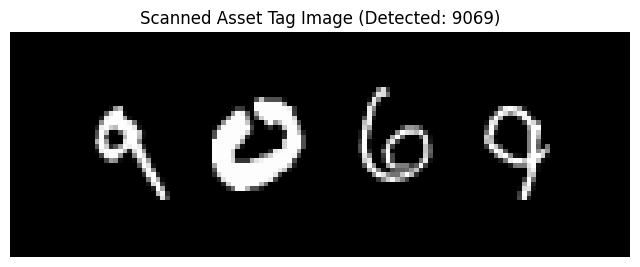

In [5]:
import numpy as np
import cv2
import json
from datetime import datetime
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import mnist

# ==========================================
# STEP 1: Train & Save the Industrial OCR Model
# (Based on your provided CNN architecture)
# ==========================================

def train_and_save_model(model_path="industry_ocr_model.keras"):
    print("[INFO] Loading dataset and training CNN model...")
    (x_train, y_train), (x_test, y_test) = mnist.load_data()

    # Normalization & Reshaping
    x_train = (x_train / 255.0).reshape(-1, 28, 28, 1)
    x_test = (x_test / 255.0).reshape(-1, 28, 28, 1)

    # Building CNN matching your design
    model = models.Sequential([
        layers.Conv2D(16, (3, 3), activation="relu", input_shape=(28, 28, 1)),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(32, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(64, activation="relu"),
        layers.Dense(10, activation="softmax")
    ])

    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    model.fit(x_train, y_train, epochs=5, validation_data=(x_test, y_test))

    # Save trained model for edge deployment (AGVs / Microcontrollers)
    model.save(model_path)
    print(f"[INFO] Model successfully saved to '{model_path}'.\n")
    return model

# ==========================================
# STEP 2: Synthetic Industrial Serial Tag Generator
# (Simulates an AGV/AMR camera capturing a tag on a container)
# ==========================================

def generate_mock_asset_tag(digits_indices=[0, 25, 100, 999]):
    """
    Stitches multiple MNIST test images together to simulate
    a multi-digit asset tracking code (e.g., container ID / serial number).
    """
    (_, _), (x_test, y_test) = mnist.load_data()

    selected_images = [x_test[idx] for idx in digits_indices]
    actual_labels = [y_test[idx] for idx in digits_indices]

    # Concatenate horizontally to form a continuous serial plate
    asset_tag_image = np.hstack(selected_images)

    # Add artificial padding/border to mimic a physical label
    asset_tag_image = cv2.copyMakeBorder(
        asset_tag_image, 10, 10, 10, 10, cv2.BORDER_CONSTANT, value=0
    )

    expected_code = "".join(map(str, actual_labels))
    return asset_tag_image, expected_code

# ==========================================
# STEP 3: Image Segmentation Pipeline
# (Crops individual digits from the scanned label)
# ==========================================

def segment_digits_from_tag(tag_image):
    """
    Finds bounding boxes around digits, crops them, and reshapes to 28x28.
    """
    # Thresholding to isolate digit contours
    _, thresh = cv2.threshold(tag_image, 50, 255, cv2.THRESH_BINARY)

    # Find contours (individual character regions)
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    bounding_boxes = []
    for c in contours:
        x, y, w, h = cv2.boundingRect(c)
        if w > 5 and h > 5:  # Filter out minor noise
            bounding_boxes.append((x, y, w, h))

    # Sort bounding boxes left-to-right (chronological digit order)
    bounding_boxes = sorted(bounding_boxes, key=lambda b: b[0])

    digit_images = []
    for (x, y, w, h) in bounding_boxes:
        # Extract individual digit region
        digit_crop = tag_image[y:y+h, x:x+w]

        # Resize to 28x28 standard MNIST format with zero-padding
        square_crop = cv2.resize(digit_crop, (20, 20))
        padded_digit = np.pad(square_crop, ((4, 4), (4, 4)), mode='constant', constant_values=0)

        digit_images.append(padded_digit)

    return digit_images, bounding_boxes

# ==========================================
# STEP 4: End-to-End Asset Scanning & ERP Logging
# ==========================================

def scan_and_log_asset(tag_image, model, location_id="WAREHOUSE_BAY_3"):
    """
    Processes the scanned image, predicts the serial number, and logs to ERP system.
    """
    digit_crops, _ = segment_digits_from_tag(tag_image)
    predicted_serial = ""

    for digit_crop in digit_crops:
        # Normalize and reshape for model input (1, 28, 28, 1)
        input_tensor = (digit_crop / 255.0).reshape(1, 28, 28, 1)
        prediction = model.predict(input_tensor, verbose=0)
        predicted_digit = np.argmax(prediction)
        predicted_serial += str(predicted_digit)

    # Generate JSON log entry for Smart Factory ERP / Supply Chain Database
    log_entry = {
        "timestamp": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
        "location": location_id,
        "scanned_serial_number": predicted_serial,
        "status": "VERIFIED_INVENTORY"
    }

    return predicted_serial, log_entry

# ==========================================
# STEP 5: Execution & Demonstration
# ==========================================

if __name__ == "__main__":
    # 1. Train and load model
    model = train_and_save_model()

    # 2. Simulate an AGV scanner reading a serial plate using test indices from your original code
    sample_indices = [7, 25, 100, 999]  # Indices corresponding to specific test digits
    asset_tag, actual_code = generate_mock_asset_tag(sample_indices)

    # 3. Perform Industry 4.0 OCR scan
    detected_serial, erp_log = scan_and_log_asset(asset_tag, model, location_id="AGV_ROBOT_01")

    # 4. Display Results
    print("=" * 50)
    print("INDUSTRY 4.0 ASSET TRACKING SCAN RESULTS")
    print("=" * 50)
    print(f"Ground Truth Serial Tag Code : {actual_code}")
    print(f"Scanned & Predicted Code     : {detected_serial}")
    print("-" * 50)
    print("Simulated ERP System Database Log:")
    print(json.dumps(erp_log, indent=4))
    print("=" * 50)

    # Plot original scanned tag image
    plt.figure(figsize=(8, 3))
    plt.imshow(asset_tag, cmap="gray")
    plt.title(f"Scanned Asset Tag Image (Detected: {detected_serial})")
    plt.axis("off")
    plt.show()


In [7]:
import app
app.MODEL = model
app.build_ui().launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://3da402fe399cbfe3cb.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


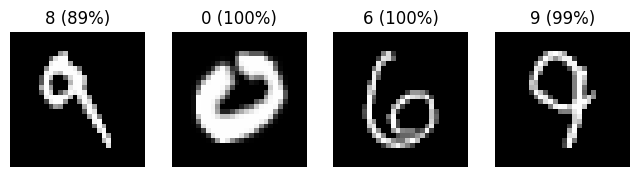

Scores for first digit: [0.    0.    0.    0.    0.    0.    0.    0.    0.892 0.107]
Original MNIST picture, no cutting: 9 100 %


In [8]:
import numpy as np
import matplotlib.pyplot as plt

x_test = app.get_mnist_test()[0]
tag, truth = app.make_mnist_tag([7, 25, 100, 999])
digs, boxes = app.segment_digits(tag)
probs = model.predict(np.array(digs).reshape(-1, 28, 28, 1) / 255.0, verbose=0)

fig, ax = plt.subplots(1, 4, figsize=(8, 2.5))
for i in range(4):
    ax[i].imshow(digs[i], cmap="gray")
    ax[i].set_title(f"{probs[i].argmax()} ({probs[i].max()*100:.0f}%)")
    ax[i].axis("off")
plt.show()

print("Scores for first digit:", np.round(probs[0], 3))
direct = model.predict((x_test[7] / 255.0).reshape(1, 28, 28, 1), verbose=0)
print("Original MNIST picture, no cutting:", direct.argmax(), round(float(direct.max()) * 100), "%")

In [10]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import mnist
import app

tf.keras.utils.set_random_seed(7)   # same result every time you run it

(x_train, y_train), (x_test, y_test) = mnist.load_data()
x_train = (x_train / 255.0).reshape(-1, 28, 28, 1)
x_test = (x_test / 255.0).reshape(-1, 28, 28, 1)

model = models.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(16, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(10, activation="softmax"),
])
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.fit(x_train, y_train, epochs=8, validation_data=(x_test, y_test))
model.save("industry_ocr_model.keras")

# check the demo tag
app.MODEL = model
_, text, _ = app.demo_tag("7, 25, 100, 999")
print(text)

app.build_ui().launch(share=True)

Epoch 1/8
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 37s 19ms/step - accuracy: 0.9448 - loss: 0.1820 - val_accuracy: 0.9838 - val_loss: 0.0522
Epoch 2/8
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 34s 18ms/step - accuracy: 0.9831 - loss: 0.0556 - val_accuracy: 0.9869 - val_loss: 0.0383
Epoch 3/8
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 34s 18ms/step - accuracy: 0.9882 - loss: 0.0381 - val_accuracy: 0.9871 - val_loss: 0.0350
Epoch 4/8
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 34s 18ms/step - accuracy: 0.9913 - loss: 0.0283 - val_accuracy: 0.9877 - val_loss: 0.0344
Epoch 5/8
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 33s 18ms/step - accuracy: 0.9934 - loss: 0.0216 - val_accuracy: 0.9882 - val_loss: 0.0371
Epoch 6/8
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 35s 19ms/step - accuracy: 0.9944 - loss: 0.0174 - val_accuracy: 0.9889 - val_loss: 0.0356
Epoch 7/8
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 41s 19ms/step - accuracy: 0.9958 - loss: 0.0144 - val_accuracy: 0.9870 - val_loss: 0.0437
Epoch 8/8
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 34s 18ms/step - accuracy: 0.9965 - loss: 0

Actual code on tag      : 9069  ->  MATCH
Predicted serial number : 9069
Digit confidence (%)    : 100, 100, 100, 96
Inventory check         : ACCEPTED - item found in inventory
Storage location        : Shelf B2
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://31b09c3fdbbb834665.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
